Grid Size : 400 x 800
Auto-detected Start : (10, 10)
Auto-detected End   : (390, 790)
Running A*...
Path found! Length: 957 steps | Total Cost: 17620


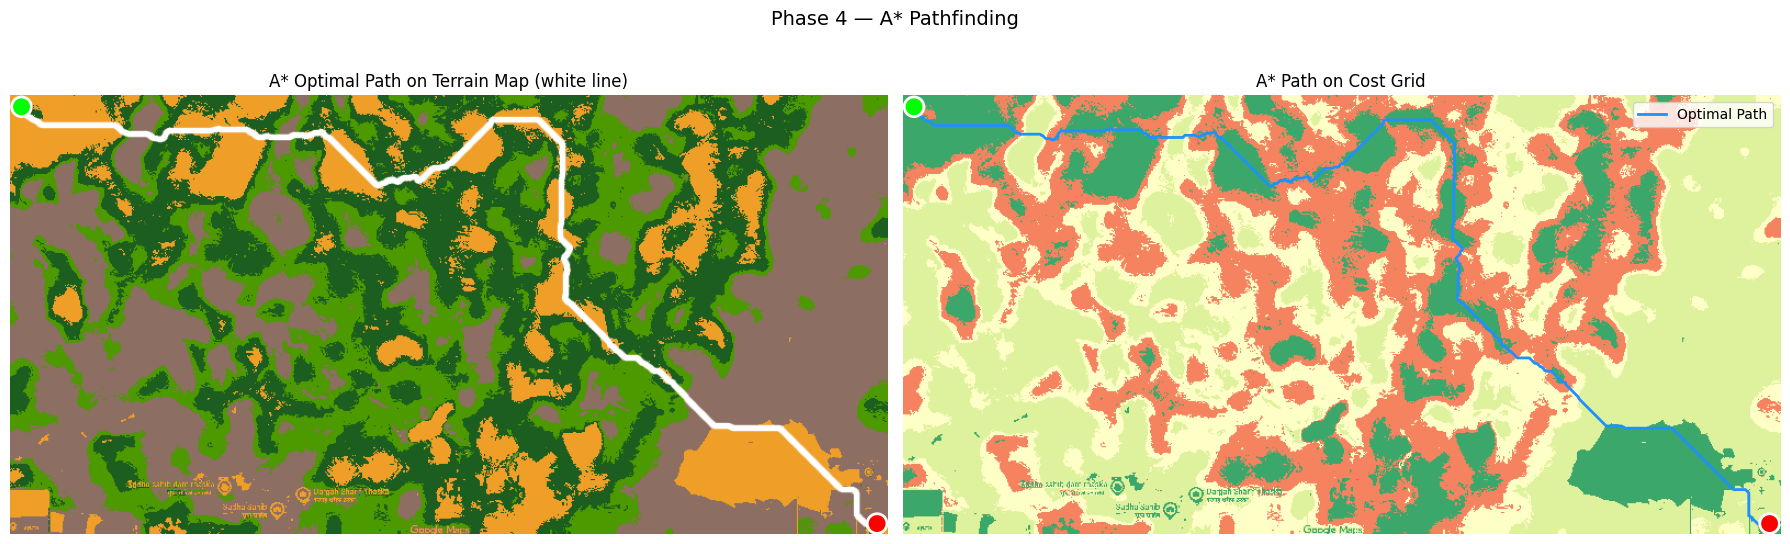


Terrain Breakdown Along Path:
Terrain       Steps       %   Cost   Subtotal
---------------------------------------------
open_land       778   81.3%     10       7780
rocky            73    7.6%     40       2920
forest           54    5.6%     80       4320
vegetation       52    5.4%     50       2600

Total Path Cost : 17620
Path Length     : 957 steps
Terrains Crossed: 4


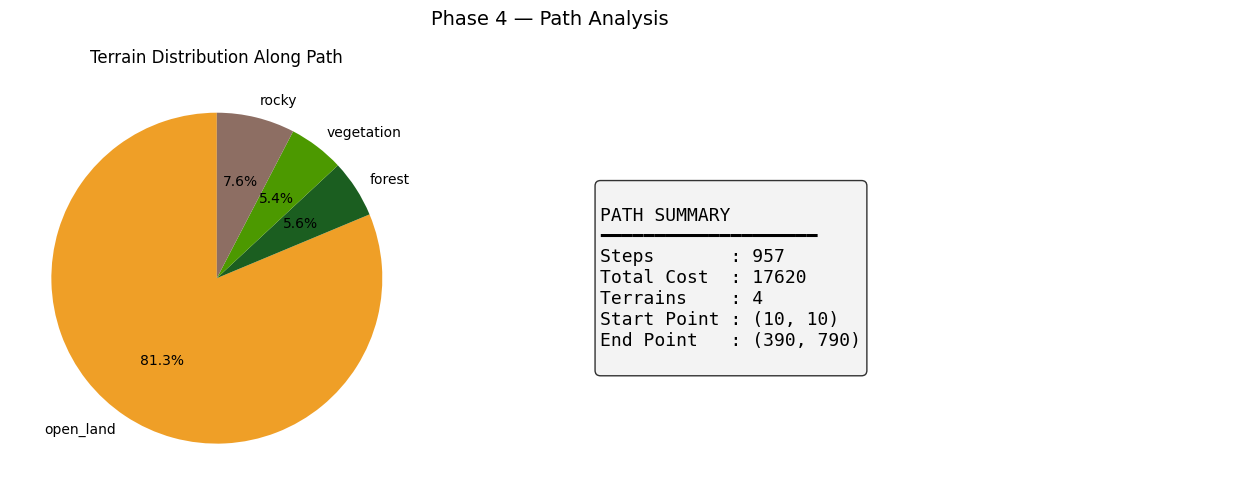

path.npy saved!


In [1]:
import numpy as np
import heapq
import matplotlib.pyplot as plt
import cv2

# ── LOAD DATA ────────────────────────────────────────────
cost_grid   = np.load(r"F:\resume project\path project\input\cost_grid.npy")
terrain_map = np.load(r"F:\resume project\path project\input\terrain_map.npy")

# Terrain definitions (needed for breakdown stats)
TERRAIN = {
    "water":      {"cost": 9999, "color": [41,  120, 200]},
    "forest":     {"cost": 80,   "color": [27,  94,  32]},
    "vegetation": {"cost": 50,   "color": [76,  153, 0]},
    "rocky":      {"cost": 40,   "color": [141, 110, 99]},
    "urban":      {"cost": 5,    "color": [150, 150, 150]},
    "open_land":  {"cost": 10,   "color": [239, 159, 39]},
}

H, W = cost_grid.shape
print(f"Grid Size : {H} x {W}")
# ── AUTO START/END DETECTION ────────────────────────────
# Snaps to nearest non-water pixel from corners

def find_start_end(grid):
    H, W = grid.shape

    def nearest_passable(r, c):
        for d in range(max(H, W)):
            for dr in range(-d, d + 1):
                for dc in range(-d, d + 1):
                    nr, nc = r + dr, c + dc
                    if 0 <= nr < H and 0 <= nc < W and grid[nr, nc] < 9999:
                        return (nr, nc)
        return (r, c)

    return nearest_passable(10, 10), nearest_passable(H - 10, W - 10)

START, END = find_start_end(cost_grid)
print(f"Auto-detected Start : {START}")
print(f"Auto-detected End   : {END}")
# ── A* ALGORITHM ─────────────────────────────────────────
# Key upgrades vs basic A*:
#   1. Water (cost >= 9999) treated as HARD WALLS — completely skipped
#   2. Heuristic scaled by MIN_COST (5) → admissible (never overestimates)
#   3. Diagonal moves cost 1.414x more (Euclidean distance)

MIN_COST = 5  # urban cost — used to keep heuristic admissible

def heuristic(a, b):
    return MIN_COST * np.sqrt((a[0]-b[0])**2 + (a[1]-b[1])**2)

def astar(grid, start, end):
    H, W = grid.shape
    INF  = float('inf')

    heap = [(0.0, start)]
    came = {}
    g    = {start: 0.0}

    dirs = [(-1,0),(1,0),(0,-1),(0,1),
            (-1,-1),(-1,1),(1,-1),(1,1)]

    while heap:
        _, cur = heapq.heappop(heap)

        if cur == end:
            path = []
            while cur in came:
                path.append(cur)
                cur = came[cur]
            path.append(start)
            return path[::-1]

        for dr, dc in dirs:
            nb = (cur[0]+dr, cur[1]+dc)
            if not (0 <= nb[0] < H and 0 <= nb[1] < W):
                continue

            nb_cost = grid[nb[0], nb[1]]

            # Hard wall — skip water entirely
            if nb_cost >= 9999:
                continue

            move_cost = nb_cost * (1.414 if dr and dc else 1.0)
            tg = g[cur] + move_cost

            if tg < g.get(nb, INF):
                came[nb] = cur
                g[nb]    = tg
                f        = tg + heuristic(nb, end)
                heapq.heappush(heap, (f, nb))

    return []  # no path found

print("Running A*...")
path = astar(cost_grid, START, END)

if path:
    total_cost = sum(cost_grid[r, c] for r, c in path)
    print(f"Path found! Length: {len(path)} steps | Total Cost: {total_cost:.0f}")
else:
    print("No path found!")
# ── DRAW THICK VISIBLE PATH ─────────────────────────────
def draw_path_thick(image, path, thickness=3):
    overlay = image.copy()
    if len(path) < 2:
        return overlay
    pts = np.array([[c, r] for r, c in path], dtype=np.int32)
    cv2.polylines(overlay, [pts], isClosed=False,
                  color=(255, 255, 255), thickness=thickness, lineType=cv2.LINE_AA)
    return overlay

overlay = draw_path_thick(terrain_map, path, thickness=3)

# ── VISUALIZE PATH ───────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Left: path on terrain color map
axes[0].imshow(overlay)
axes[0].scatter([START[1], END[1]], [START[0], END[0]],
                c=['lime', 'red'], s=200, zorder=5, edgecolors='white', lw=2)
axes[0].set_title("A* Optimal Path on Terrain Map (white line)")
axes[0].axis('off')

# Right: path on cost grid
display_grid = np.clip(cost_grid, 0, 100)
axes[1].imshow(display_grid, cmap='RdYlGn_r', vmin=0, vmax=100, alpha=0.85)
path_rows, path_cols = zip(*path)
axes[1].plot(path_cols, path_rows, color='dodgerblue', lw=2, label='Optimal Path')
axes[1].scatter([START[1], END[1]], [START[0], END[0]],
                c=['lime', 'red'], s=200, zorder=5, edgecolors='white', lw=2)
axes[1].set_title("A* Path on Cost Grid")
axes[1].axis('off')
axes[1].legend()

plt.suptitle("Phase 4 — A* Pathfinding", fontsize=14)
plt.tight_layout()
plt.show()
# ── TERRAIN BREAKDOWN ALONG PATH ────────────────────────
cost_to_name = {v["cost"]: k for k, v in TERRAIN.items()}
counts = {}
for r, c in path:
    name = cost_to_name.get(int(cost_grid[r, c]), "unknown")
    counts[name] = counts.get(name, 0) + 1

print("\nTerrain Breakdown Along Path:")
print(f"{'Terrain':<12} {'Steps':>6} {'%':>7} {'Cost':>6} {'Subtotal':>10}")
print("-" * 45)
for name, steps in sorted(counts.items(), key=lambda x: -x[1]):
    pct      = steps / len(path) * 100
    cost     = TERRAIN.get(name, {}).get("cost", 0)
    subtotal = steps * cost
    print(f"{name:<12} {steps:>6} {pct:>6.1f}% {cost:>6} {subtotal:>10}")
print(f"\nTotal Path Cost : {total_cost:.0f}")
print(f"Path Length     : {len(path)} steps")
print(f"Terrains Crossed: {len(counts)}")

# ── PIE CHART ────────────────────────────────────────────
labels = list(counts.keys())
sizes  = list(counts.values())
clrs   = [np.array(TERRAIN[n]["color"])/255 if n in TERRAIN else [0.5,0.5,0.5] for n in labels]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].pie(sizes, labels=labels, colors=clrs, autopct='%1.1f%%', startangle=90)
axes[0].set_title("Terrain Distribution Along Path")

# Summary metrics
axes[1].axis('off')
summary = f"""
PATH SUMMARY
━━━━━━━━━━━━━━━━━━━━
Steps       : {len(path)}
Total Cost  : {total_cost:.0f}
Terrains    : {len(counts)}
Start Point : {START}
End Point   : {END}
"""
axes[1].text(0.1, 0.5, summary, fontsize=13, verticalalignment='center',
             fontfamily='monospace',
             bbox=dict(boxstyle='round', facecolor='#f0f0f0', alpha=0.8))

plt.suptitle("Phase 4 — Path Analysis", fontsize=14)
plt.tight_layout()
plt.show()

# ── SAVE PATH ────────────────────────────────────────────
np.save(r"F:\resume project\path project\input\path.npy", np.array(path))
print("path.npy saved!")
